# 기초데이터과학 (01분반)

## 12-1. 데이터 분석 케이스 스터디 1
### 따릉이 대여량: 분석 절차 따라가기

#### 데이터 분석 단계
| 단계 | 할 일 | 관련 부분 |
|---|---|---|
| 1. 질문 | 무엇을 알아내려는지 한 문장으로 정함 | |
| 2. 데이터 확인 | 크기, 변수, 자료형, 결측치 확인 | Series 와 DataFrame, 데이터 전처리 |
| 3. 정제 | 결측치, 이상치, 존재할 수 없는 값을 판단하고 처리 | 데이터 정제 |
| 4. 탐색 | 집계와 그래프로 패턴 확인 | 데이터 가공, 데이터 시각화 |
| 5. 근거 | 상관 분석, 가설 검정으로 판단 | 상관 분석과 가설 검정 |
| 6. 결론과 한계 | 알게 된 것과 이 분석으로 말할 수 없는 것을 정리 | |

- 각 단계에서 정답이 정해져 있지 않은 **판단**이 필요함. 판단한 이유를 함께 기록하는 것이 중요함

### 상황

- 여러분은 서울시 공공자전거 **따릉이 운영팀**에 새로 들어온 데이터 분석 담당자입니다.
- 팀장이 다음과 같은 분석 업무를 요청했습니다.

> "자전거를 언제, 얼마나 준비해 둬야 하는지 계획을 세우려고 합니다.
> 날씨와 요일에 따라 대여량이 어떻게 달라지는지 지난 1년 기록으로 분석해 주세요."

- 분석 결과는 팀장에게 **결론과 한계**로 정리하여 보고해야 합니다.

### 오늘의 질문

> **따릉이의 대여량은 날씨와 요일에 따라 어떻게 달라지는가?**

#### 데이터
- 2017년 12월 1일 ~ 2018년 11월 30일의 시간별 따릉이 대여량과 날씨 정보
- 출처: Seoul Bike Sharing Demand, UCI Machine Learning Repository (CC BY 4.0)
  - https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand
  - 원본의 열 이름을 짧은 영문으로 바꾸어 정리한 파일을 사용함

| 주요 변수 | 의미 |
|---|---|
| `date` | 날짜 (일/월/연) |
| `count` | 해당 시간대의 대여량 |
| `hour` | 시각 (0 ~ 23) |
| `temp` | 기온 (섭씨) |
| `humidity`, `wind` | 습도 (%), 풍속 (m/s) |
| `rain`, `snow` | 강수량 (mm), 적설량 (cm) |
| `season` | 계절 (Winter, Spring, Summer, Autumn) |
| `holiday` | 공휴일 여부 |
| `functioning` | 대여소 운영 여부 (Yes, No) |

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

bike = pd.read_csv('seoul_bike.csv')
print(bike.head())
print()
print(bike.dtypes)

         date  count  hour  temp  humidity  wind  visibility  dew_point  \
0  01/12/2017    254     0  -5.2        37   2.2        2000      -17.6   
1  01/12/2017    204     1  -5.5        38   0.8        2000      -17.6   
2  01/12/2017    173     2  -6.0        39   1.0        2000      -17.7   
3  01/12/2017    107     3  -6.2        40   0.9        2000      -17.6   
4  01/12/2017     78     4  -6.0        36   2.3        2000      -18.6   

   solar  rain  snow  season     holiday functioning  
0    0.0   0.0   0.0  Winter  No Holiday         Yes  
1    0.0   0.0   0.0  Winter  No Holiday         Yes  
2    0.0   0.0   0.0  Winter  No Holiday         Yes  
3    0.0   0.0   0.0  Winter  No Holiday         Yes  
4    0.0   0.0   0.0  Winter  No Holiday         Yes  

date               str
count            int64
hour             int64
temp           float64
humidity         int64
wind           float64
visibility       int64
dew_point      float64
solar          float64
rain       

---

## 날짜 데이터 다루기

- `date` 열의 자료형이 문자열임
  - pandas 버전에 따라 `object` 또는 `str` 로 표시됨
- 문자열로는 "몇 월인지", "무슨 요일인지"를 알 수 없음
- pandas 의 날짜 자료형(`datetime`)으로 바꾸어야 함

- 첫 행의 날짜는 `01/12/2017` 임
- 이 값은 2017년 **1월 12일**일까, **12월 1일**일까?

In [2]:
print(pd.to_datetime('01/12/2017'))

2017-01-12 00:00:00


<details>
<summary><b>내용 보기</b> (클릭)</summary>

- pandas 는 기본적으로 **월/일/연** 순서로 해석하여 1월 12일로 바꿈
- 그런데 이 데이터는 2017년 12월부터 시작하므로 실제로는 **일/월/연** 순서임

</details>

- 여러 날짜를 한꺼번에 바꾸면 어떻게 될까?

In [3]:
sample = pd.Series(['01/12/2017', '02/12/2017', '13/12/2017'])

try:
    print(pd.to_datetime(sample))
except Exception as e:
    print("오류 발생:", type(e).__name__)

오류 발생: ValueError


<details>
<summary><b>내용 보기</b> (클릭)</summary>

- 13 은 월이 될 수 없으므로 오류가 남
- 만약 데이터에 12일 이하의 날짜만 있었다면 오류 없이 **날짜가 틀리게** 바뀌었을 것임
- 날짜를 바꿀 때는 `format` 으로 순서를 직접 지정하는 것이 안전함

| 기호 | 의미 | 예 |
|---|---|---|
| `%Y` | 네 자리 연도 | 2017 |
| `%m` | 월 (두 자리) | 12 |
| `%d` | 일 (두 자리) | 01 |
| `%H` | 시 (24시간) | 18 |

</details>

In [4]:
print(pd.to_datetime(sample, format='%d/%m/%Y'))

0   2017-12-01
1   2017-12-02
2   2017-12-13
dtype: datetime64[us]


In [5]:
bike['date'] = pd.to_datetime(bike['date'], format='%d/%m/%Y')

print(bike['date'].dtype)
print(bike['date'].min(), '~', bike['date'].max())

datetime64[us]
2017-12-01 00:00:00 ~ 2018-11-30 00:00:00


#### 날짜에서 정보 뽑기
- 날짜 자료형의 열에 `.dt` 를 붙이면 연, 월, 요일 등을 꺼낼 수 있음

| 코드 | 결과 |
|---|---|
| `.dt.year` | 연도 |
| `.dt.month` | 월 (1 ~ 12) |
| `.dt.day` | 일 |
| `.dt.dayofweek` | 요일 번호 (월요일 0 ~ 일요일 6) |
| `.dt.day_name( )` | 요일 이름 (Monday, ...) |

In [6]:
bike = bike.assign(month   = lambda x: x['date'].dt.month,
                   weekday = lambda x: x['date'].dt.day_name(),
                   weekend = lambda x: x['date'].dt.dayofweek >= 5)   # 토요일(5), 일요일(6)

print(bike[['date', 'month', 'weekday', 'weekend']].drop_duplicates().head(8))

          date  month    weekday  weekend
0   2017-12-01     12     Friday    False
24  2017-12-02     12   Saturday     True
48  2017-12-03     12     Sunday     True
72  2017-12-04     12     Monday    False
96  2017-12-05     12    Tuesday    False
120 2017-12-06     12  Wednesday    False
144 2017-12-07     12   Thursday    False
168 2017-12-08     12     Friday    False


- `drop_duplicates( )` : 중복된 행을 제거함. 하루에 24행씩 있어서 날짜별로 한 행만 보기 위해 사용
- 주말 여부(`weekend`)는 요일 번호가 5 이상인지로 만듦

---

## 사례: 따릉이 대여량 분석 (1부)

### 단계 2. 데이터 확인

In [7]:
print(bike.shape)
print()
print(bike.isna().sum().sum(), "개의 결측치")
print()
print(bike['count'].describe().round(1))

(8760, 17)

0 개의 결측치

count    8760.0
mean      704.6
std       645.0
min         0.0
25%       191.0
50%       504.5
75%      1065.2
max      3556.0
Name: count, dtype: float64


- 8,760 행 = 365일 × 24시간. 한 행이 한 시간을 나타냄
- 결측치는 없음
- 대여량의 최솟값이 0 임. 따릉이를 한 시간 동안 아무도 빌리지 않는 경우가 있을까?

### 단계 3. 정제 — 판단이 필요한 값

In [8]:
print(bike['functioning'].value_counts()) # value_counts() 함수: 값마다 몇 개씩 있는지 세어 개수를 반환
print()
print("운영하지 않은 시간의 대여량 합계:", bike.query('functioning == "No"')['count'].sum())
print("운영하지 않은 날의 수:", bike.query('functioning == "No"')['date'].nunique()) # nunique() 함수: 서로 다른 값이 몇 개인지 세어 개수를 반환

functioning
Yes    8465
No      295
Name: count, dtype: int64

운영하지 않은 시간의 대여량 합계: 0
운영하지 않은 날의 수: 13


#### 판단해 볼 것
- 대여소를 운영하지 않은 295 시간은 대여량이 모두 0 임
- 이 0 을 그대로 두고 분석해도 될까?

> 나의 판단과 이유: 운영하지 않은 시간의 0건은 수요가 없었다는 관측이 아니라 대여가 불가능했던 결과이다. 따라서 날씨·요일에 따른 수요 비교에서 제외한다.

<details>
<summary><b>판단의 근거 보기</b> (클릭)</summary>

- 이 0 은 "아무도 빌리지 않았다"가 아니라 **"빌릴 수 없었다"** 는 뜻
- 그대로 두면 평균 대여량이 실제보다 낮아지고, 날씨와 대여량의 관계도 흐려짐
- 데이터 정제에서 다룬 "존재할 수 없는 값"과 비슷한 성격이므로 **분석에서 제외**함
- 이렇게 판단한 내용과 이유는 분석 결과와 함께 기록해 두어야 함

</details>

In [9]:
bike = bike.query('functioning == "Yes"')
print(bike.shape)

(8465, 17)


### 단계 4. 탐색 — 하루 중 언제 많이 빌리는가?

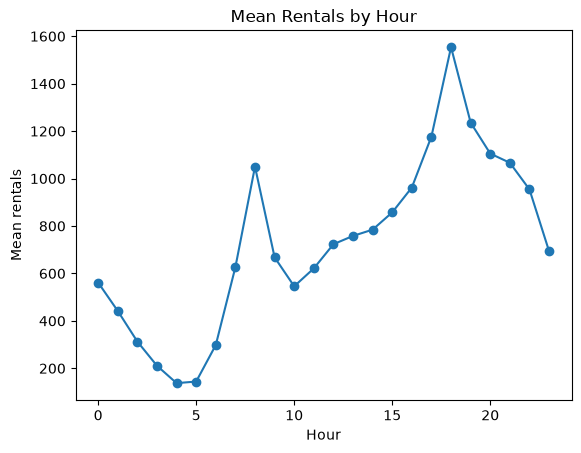

In [10]:
by_hour = bike.groupby('hour')['count'].mean()

plt.plot(by_hour.index, by_hour.values, marker='o')
plt.title('Mean Rentals by Hour')
plt.xlabel('Hour')
plt.ylabel('Mean rentals')
plt.show()

<details>
<summary><b>내용 보기</b> (클릭)</summary>
    
- 오전 8시와 오후 6시에 뚜렷한 봉우리가 있음
- **출퇴근 시간**에 많이 빌린다는 뜻. 따릉이가 여가뿐 아니라 통근 수단으로도 쓰이고 있음
- 이 결과는 실습의 "주말과 평일" 문제를 해석할 때 다시 쓰게 됨

</details>

### 단계 4. 탐색 — 기온과 대여량의 관계

- 시간 단위 데이터로 기온과 대여량을 바로 비교하면, 같은 날이라도 새벽과 저녁의 대여량 차이가 섞여 들어감
- 날씨의 영향을 보려면 **하루 단위로 집계**하는 것이 알맞음

In [11]:
daily = bike.groupby('date').agg(count=('count', 'sum'),
                                 temp=('temp', 'mean')).reset_index()

print(daily.shape)
print(daily.head())

(353, 3)
        date  count      temp
0 2017-12-01   9539 -2.454167
1 2017-12-02   8523  1.325000
2 2017-12-03   7222  4.875000
3 2017-12-04   8729 -0.304167
4 2017-12-05   8307 -4.458333


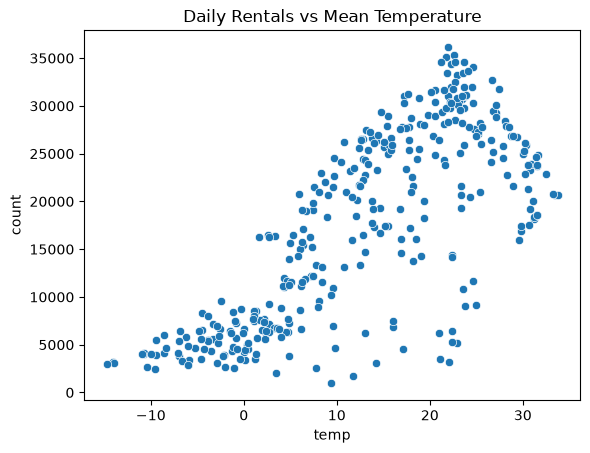

상관계수: 0.753


In [12]:
sns.scatterplot(data=daily, x='temp', y='count')

plt.title('Daily Rentals vs Mean Temperature')
plt.show()

print("상관계수:", round(daily['temp'].corr(daily['count']), 3))

<details>
<summary><b>내용 보기</b> (클릭)</summary>
    
- 상관계수가 약 0.75 로 강한 양의 상관관계
- 그런데 산점도를 자세히 보면 오른쪽 끝에서 대여량이 다시 줄어드는 것처럼 보임
- 기온 구간별 평균으로 확인해 봄

</details>

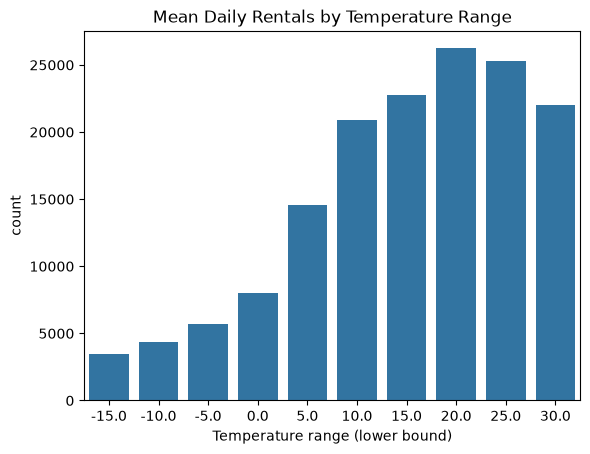

In [13]:
# 기온을 5도 간격의 구간으로 묶은 뒤, 구간마다 평균 대여량을 막대로 그려보자

daily = daily.assign(temp_bin = lambda x: (x['temp'] // 5) * 5)    # 5도 간격의 구간을 만들어서 temp_bin 열로 할당

sns.barplot(data=daily, x='temp_bin', y='count', errorbar=None)    # temp_bin이 같은 날들끼리 count의 평균을 구해 막대로 표현

plt.title('Mean Daily Rentals by Temperature Range')
plt.xlabel('Temperature range (lower bound)')
plt.show()

<details>
<summary><b>내용 보기</b> (클릭)</summary>

- 20 ~ 25도 구간까지는 기온이 오를수록 대여량이 늘지만, 25도를 넘으면 오히려 줄어듦
- 상관계수 0.75 만 보고 "기온이 높을수록 많이 빌린다"고 결론 내리면 틀림
  - 11주차 예제 2 의 **도중에 방향이 바뀌는 관계**와 같은 모양임. 상관계수는 이런 관계를 제대로 나타내지 못함
  - 11주차 Anscombe 데이터의 교훈과 같음: **상관계수만 보지 말고 모양을 확인할 것**

</details>

---

### 지금까지의 판단 정리

| 단계 | 판단 | 이유 |
|---|---|---|
| 날짜 변환 | `format='%d/%m/%Y'` 지정 | 일/월/연 순서. 지정하지 않으면 틀리게 바뀌거나 오류 |
| 정제 | 운영하지 않은 시간 제외 | "빌릴 수 없었던" 0 이므로 |
| 집계 단위 | 날씨와의 관계는 하루 단위로 | 시간대에 따른 차이가 섞이지 않도록 |
| 해석 | 기온과의 관계는 직선이 아님 | 25도 이상에서 감소 |

### 팀장 보고 내용 (예시)

- 강의에서 확인한 기온과 대여량의 관계를 보고 형식으로 정리하면 다음과 같음

| 구분 | 내용 |
|---|---|
| 결론 (사실) | 하루 평균 기온 20 ~ 25도까지는 기온이 오를수록 대여량이 늘었으나, 25도를 넘으면 오히려 줄었음 (기온 구간별 평균 그래프). 상관계수 0.75 만으로는 이 관계를 제대로 나타낼 수 없음 |
| 제안 | 여름철 대여 수요를 예측할 때 "기온이 높을수록 많이 빌린다"고 가정하지 않도록 검토할 수 있음 |
| 한계 | 1년 치 기록만 사용했으므로, 다른 해의 여름에도 같은 경향이 나타나는지는 알 수 없음 |

- 결론에는 **근거가 된 수치나 그래프**를 함께 씀
- 제안은 "...을 해야 함"이 아니라 **"...을 검토할 수 있음"** 처럼 씀. 데이터가 보여 주는 것은 관계이지 원인이 아니기 때문

### 실습에서 이어서 확인하는 질문
- 비가 오면 대여량이 줄어드는가?
- 주말에는 평일보다 많이 빌리는가?
- 계절에 따라 기온과 대여량의 관계가 달라지는가?
- 분석 결과를 바탕으로 팀장에게 보고할 결론과 한계를 작성
  - 데이터에서 확인한 **사실**과 그에 따른 **제안**을 구분하여 쓸 것

---

## 후속 분석 실습 풀이

**분석 기준:** 운영 중인 시간만 사용한다. 일별 대여량 비교에서는 24시간 모두 운영한 날만 남겨, 운영 시간이 짧아서 대여량 합계가 작아지는 영향을 피한다. 비가 온 날은 운영 시간 중 강수량이 한 번이라도 0 mm보다 큰 날로 정의한다. 이 기준에 따라 352일을 비교한다.

In [14]:
from scipy import stats

# 앞의 강의 셀을 순서대로 실행하여 bike의 날짜·요일 변환과 운영 시간 필터를 적용한다.
daily_case = bike.groupby('date').agg(
    count=('count', 'sum'),
    operating_hours=('count', 'size'),
    temp=('temp', 'mean'),
    rain_total=('rain', 'sum'),
    season=('season', 'first'),
    weekend=('weekend', 'first'),
    holiday=('holiday', 'first')
).reset_index()

daily_case = daily_case.loc[daily_case['operating_hours'].eq(24)].copy()
daily_case['rainy'] = daily_case['rain_total'].gt(0)
full_hours = bike.loc[bike['date'].isin(daily_case['date'])].copy()

print('분석 대상 일수:', len(daily_case))
print('운영하지 않은 시간:', 8760 - len(bike))
print('제외된 날짜:', 365 - len(daily_case))

분석 대상 일수: 352
운영하지 않은 시간: 295
제외된 날짜: 13


### 1. 비가 오면 대여량이 줄어드는가?

비가 온 날과 오지 않은 날의 **하루 대여량 합계**를 비교한다. 두 집단의 평균 차이에 대해서는 11주차 강의의 독립표본 t 검정을 사용하되, 분산이 같다고 가정하지 않는 Welch 방식(`equal_var=False`)을 적용한다.

- 귀무가설: 두 집단의 평균 하루 대여량은 같다.
- 대립가설: 두 집단의 평균 하루 대여량은 다르다.

       size     mean   median
rainy                        
False   253  18695.4  20794.0
True     99  14407.6  13790.0
비 온 날 - 안 온 날: -4,287.8건 (-22.9%)
Welch t 검정 p값: 0.000208


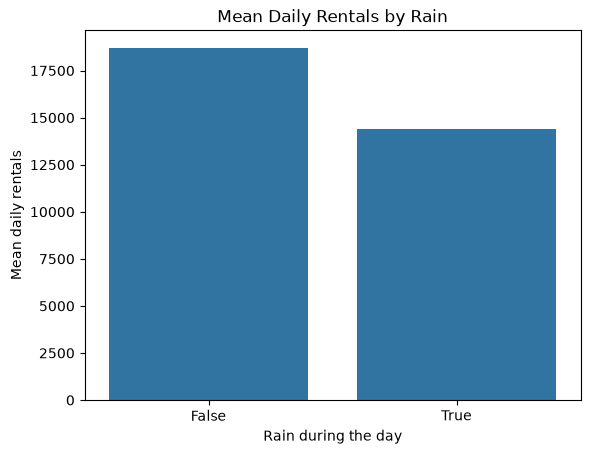

In [15]:
rain_summary = daily_case.groupby('rainy')['count'].agg(['size', 'mean', 'median'])
print(rain_summary.round(1))

rainy_counts = daily_case.loc[daily_case['rainy'], 'count']
dry_counts = daily_case.loc[~daily_case['rainy'], 'count']
rain_test = stats.ttest_ind(rainy_counts, dry_counts, equal_var=False)
rain_difference = rainy_counts.mean() - dry_counts.mean()
print(f'비 온 날 - 안 온 날: {rain_difference:,.1f}건 ({rain_difference / dry_counts.mean():.1%})')
print(f'Welch t 검정 p값: {rain_test.pvalue:.6f}')

sns.barplot(data=daily_case, x='rainy', y='count', errorbar=None)
plt.title('Mean Daily Rentals by Rain')
plt.xlabel('Rain during the day')
plt.ylabel('Mean daily rentals')
plt.show()

In [16]:
# 계절 구성이 전체 평균에 미치는 영향을 확인한다.
rain_by_season = daily_case.groupby(['season', 'rainy'])['count'].agg(['size', 'mean'])
print(rain_by_season.round(1))

              size     mean
season rainy               
Autumn False    62  23550.6
       True     18  17434.9
Spring False    62  20899.9
       True     28  11289.8
Summer False    57  27544.4
       True     35  20377.3
Winter False    72   5610.6
       True     18   4622.4


**해석:** 비가 온 99일은 하루 평균 **14,407.6건**, 비가 오지 않은 253일은 **18,695.4건**으로, 비가 온 날이 평균 **4,287.8건(22.9%) 적었다**. Welch t 검정의 p값은 약 **0.000208**로 0.05보다 작다. 이 자료에서는 평균 차이를 우연으로만 설명하기 어렵다. 계절별로 나누어 보아도 네 계절 모두 비가 온 날의 평균이 낮다.

다만 비가 온 날에 하루 종일 비가 내린 것은 아닐 수 있고, 기온·계절·공휴일 등이 함께 달라질 수 있다. 이 비교만으로 비가 대여량 감소의 *원인*이라고 단정할 수는 없다.

### 2. 주말에는 평일보다 많이 빌리는가?

먼저 하루 합계를 비교하고, 강의에서 확인한 출퇴근 시간의 봉우리가 주말에도 나타나는지 시간대별 평균으로 살펴본다.

         size     mean   median
weekend                        
False     251  17954.7  19877.0
True      101  16333.2  17388.0
주말 - 평일: -1,621.5건 (-9.0%)
Welch t 검정 p값: 0.166397


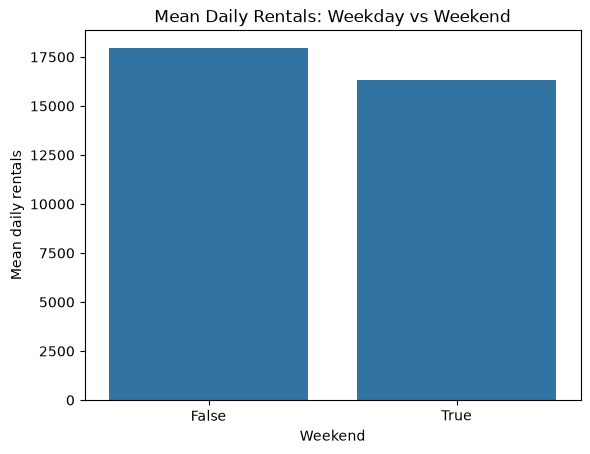

In [17]:
weekend_summary = daily_case.groupby('weekend')['count'].agg(['size', 'mean', 'median'])
print(weekend_summary.round(1))

weekend_counts = daily_case.loc[daily_case['weekend'], 'count']
weekday_counts = daily_case.loc[~daily_case['weekend'], 'count']
weekend_test = stats.ttest_ind(weekend_counts, weekday_counts, equal_var=False)
weekend_difference = weekend_counts.mean() - weekday_counts.mean()
print(f'주말 - 평일: {weekend_difference:,.1f}건 ({weekend_difference / weekday_counts.mean():.1%})')
print(f'Welch t 검정 p값: {weekend_test.pvalue:.6f}')

sns.barplot(data=daily_case, x='weekend', y='count', errorbar=None)
plt.title('Mean Daily Rentals: Weekday vs Weekend')
plt.xlabel('Weekend')
plt.ylabel('Mean daily rentals')
plt.show()

weekend   False   True 
hour                   
8        1306.0   424.9
14        721.4   940.2
18       1724.1  1126.9


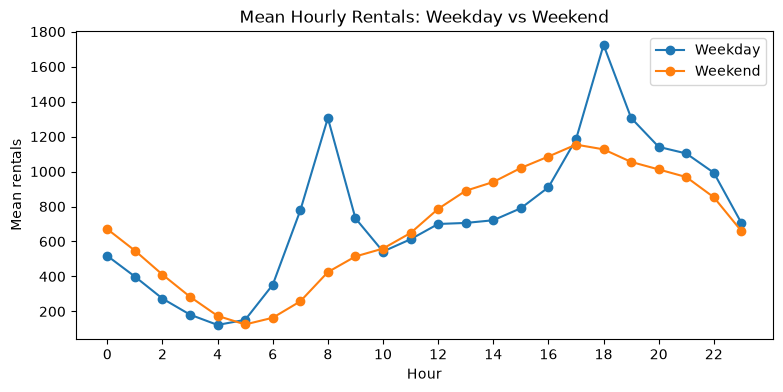

In [18]:
hourly_weekend = full_hours.groupby(['hour', 'weekend'])['count'].mean().unstack()
print(hourly_weekend.loc[[8, 14, 18]].round(1))

hourly_weekend.plot(marker='o', figsize=(9, 4))
plt.title('Mean Hourly Rentals: Weekday vs Weekend')
plt.xlabel('Hour')
plt.ylabel('Mean rentals')
plt.xticks(range(0, 24, 2))
plt.legend(['Weekday', 'Weekend'])
plt.show()

**해석:** 평일 251일의 하루 평균은 **17,954.7건**, 주말 101일은 **16,333.2건**이다. 주말이 평균 **1,621.5건(9.0%) 적었지만**, Welch t 검정의 p값은 약 **0.166**으로 0.05보다 크다. 이 검정으로는 전체 평균이 다르다고 할 충분한 근거가 없다.

시간대별로 보면 평일 오전 8시와 오후 6시에 통근 수요가 집중되고, 주말은 오전 봉우리가 약한 대신 낮과 오후의 대여량이 상대적으로 높다. 따라서 하루 총량만으로 요일별 자전거 배치 시점을 정하기는 어렵다. 여기서 평일에는 공휴일도 포함된다.

### 3. 계절에 따라 기온과 대여량의 관계가 달라지는가?

계절별 산점도와 피어슨 상관계수를 함께 확인한다. 상관계수는 직선 관계를 요약하므로 그래프의 모양도 살펴본다.

          temp      count  temp_count_r
season                                 
Winter  -2.540   5412.989         0.471
Spring  13.022  17910.100         0.654
Summer  26.583  24817.761        -0.217
Autumn  13.780  22174.562         0.551


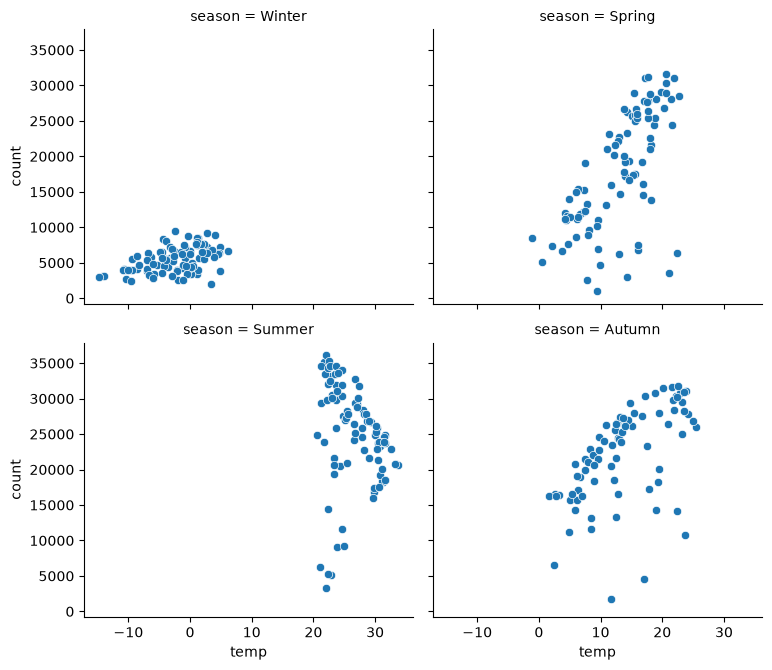

In [19]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
season_corr = daily_case.groupby('season').apply(
    lambda group: group['temp'].corr(group['count']),
    include_groups=False
).reindex(season_order)
season_means = daily_case.groupby('season')[['temp', 'count']].mean().reindex(season_order)
print(pd.concat([season_means, season_corr.rename('temp_count_r')], axis=1).round(3))

sns.relplot(
    data=daily_case, x='temp', y='count',
    col='season', col_wrap=2, col_order=season_order,
    kind='scatter', height=3.4, aspect=1.15
)
plt.show()

In [ ]:
daily_case['temp_bin'] = (daily_case['temp'] // 5) * 5
temp_by_season = daily_case.groupby(
    ['season', 'temp_bin'], observed=True
)['count'].agg(['size', 'mean'])
print(temp_by_season.round(1))

sns.relplot(
    data=temp_by_season.reset_index(), x='temp_bin', y='mean',
    col='season', col_wrap=2, col_order=season_order,
    kind='line', marker='o', height=3.4, aspect=1.15
)
plt.show()

**해석:** 계절별 기온과 대여량의 피어슨 상관계수는 **겨울 0.471, 봄 0.654, 여름 -0.217, 가을 0.551**이다. 봄·가을·겨울에는 기온이 높을수록 대여량이 대체로 증가하지만, 여름에는 오히려 약한 음의 관계가 나타난다. 특히 여름의 5도 구간별 평균은 20~25°C 구간 약 26,200건에서 30~35°C 구간 약 22,031건으로 감소한다. 계절별 기온 범위와 다른 날씨 조건이 다르므로, 상관계수의 차이만으로 기온의 인과 효과를 비교할 수는 없다.

### 4. 팀장 보고: 결론과 한계

| 구분 | 내용 |
|---|---|
| 결론: 비 | 24시간 운영한 352일 중 비가 온 99일의 일평균 대여량은 14,407.6건으로, 비가 오지 않은 253일의 18,695.4건보다 22.9% 낮았다. 계절별 비교에서도 같은 방향이었다. |
| 결론: 요일 | 주말의 일평균은 평일보다 약 9.0% 낮았으나, 전체 평균 차이에 대한 Welch 검정에서는 p=0.166으로 유의한 차이라고 판단하기 어렵다. 평일은 오전 8시·오후 6시에 뚜렷한 봉우리가 있고, 주말은 낮·오후에 상대적으로 많이 빌린다. |
| 결론: 기온 | 기온과 대여량의 관계는 계절마다 다르다. 봄에는 양의 상관(r=0.654), 여름에는 약한 음의 상관(r=-0.217)이 나타났다. 무조건 기온이 높을수록 많이 빌린다고 가정하기 어렵다. |
| 운영 제안 | 비 예보 시 대여 수요 감소 가능성을 반영하고, 평일 출퇴근 시간과 주말 낮·오후의 배치 수요를 구분해 검토할 수 있다. 여름에는 높은 기온에서 수요가 더 늘 것이라는 단순한 가정을 피한다. |
| 한계 | 2017년 12월~2018년 11월의 1년 자료이므로 다른 해에 그대로 적용하기 어렵다. 미운영 시간이 포함된 13일을 제외해 해당 기간의 수요는 평가하지 못했다. 강수 여부는 강도와 지속 시간을 구분하지 않으며, 계절·기온·공휴일 등 교란 요인을 통제하지 않았다. 연속된 날짜의 수요는 독립적이지 않을 수 있어 t 검정의 p값은 탐색적 근거로 해석한다. 관찰 자료이므로 인과 관계는 단정할 수 없다. |